In [52]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier  #평균절대값오차
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

In [53]:
## 다중회귀 - 특성이 여러 개일 때
df = pd.read_csv('data/manhattan.csv')
df.head(3)

,rental_id,rent,bedrooms,bathrooms,size_sqft,min_to_subway,floor,building_age_yrs,no_fee,has_roofdeck,has_washer_dryer,has_doorman,has_elevator,has_dishwasher,has_patio,has_gym,neighborhood,borough
0,1545,2550,0.0,1,480,9,2.0,17,1,1,0,0,1,1,0,1,Upper East Side,Manhattan
1,2472,11500,2.0,2,2000,4,1.0,96,0,0,0,0,0,0,0,0,Greenwich Village,Manhattan
2,2919,4500,1.0,1,916,2,51.0,29,0,1,0,1,1,1,0,0,Midtown,Manhattan


In [54]:
data = df.iloc[:,2:16]
label = df['rent']
data = np.array(data)
data

array([[0.00e+00, 1.00e+00, 4.80e+02, ..., 1.00e+00, 0.00e+00, 1.00e+00],
       [2.00e+00, 2.00e+00, 2.00e+03, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 9.16e+02, ..., 1.00e+00, 0.00e+00, 0.00e+00],
       ...,
       [0.00e+00, 1.00e+00, 2.50e+02, ..., 0.00e+00, 0.00e+00, 0.00e+00],
       [1.00e+00, 1.00e+00, 6.51e+02, ..., 1.00e+00, 0.00e+00, 1.00e+00],
       [1.00e+00, 1.00e+00, 8.16e+02, ..., 0.00e+00, 1.00e+00, 1.00e+00]],
      shape=(3539, 14))

In [55]:
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=3539)

In [56]:
# 1차원
lr = LinearRegression()
lr.fit(train_data, train_label)
predict = lr.predict(test_data)
# print('점수 예측: ', predict)

score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

정확도:78.11068980445015%, 77.2299724025319%


In [57]:
poly = PolynomialFeatures(degree=2,include_bias=False)  #include_bias=False 학습의미없는 데이터 1를 생략
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
# train_poly[:2]

In [58]:
# 2차원
lr = LinearRegression()
lr.fit(train_poly, train_label)
predict = lr.predict(test_poly)
# print('점수 예측: ', predict)

score = lr.score(train_poly, train_label)
score2 = lr.score(test_poly, test_label)
print(f'정확도:{score*100}%, {score2*100}%')

정확도:80.79860085975837%, 80.26140221043067%


In [59]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [60]:
alpha_list = [0.001,0.01,0.1,1,10,100]
train_score = []
test_score = []

for alpha in alpha_list:

    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled,train_label)
    score = ridge.score(train_scaled, train_label)
    score2 = ridge.score(test_scaled, test_label)
    train_score.append(score)
    test_score.append(score2)
    print(f'alpha가 {alpha}일 때 정확도: 훈련 {score*100:.1f}%, 테스트 {score2*100:.1f}%')


alpha가 0.001일 때 정확도: 훈련 81.7%, 테스트 80.5%
alpha가 0.01일 때 정확도: 훈련 81.7%, 테스트 80.5%
alpha가 0.1일 때 정확도: 훈련 81.7%, 테스트 80.5%
alpha가 1일 때 정확도: 훈련 81.7%, 테스트 80.5%
alpha가 10일 때 정확도: 훈련 81.6%, 테스트 80.5%
alpha가 100일 때 정확도: 훈련 80.6%, 테스트 79.7%


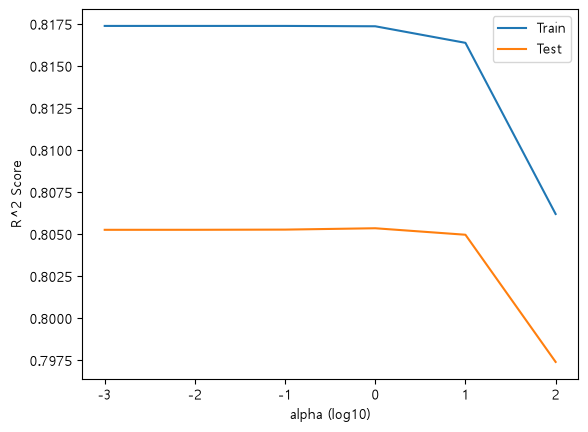

In [63]:
plt.plot(np.log10(alpha_list), train_score, label='Train')
plt.plot(np.log10(alpha_list), test_score, label='Test')
plt.xlabel('alpha (log10)')
plt.ylabel('R^2 Score')
plt.legend()
plt.show()

In [65]:
# 5. 최적의 alpha=10을 적용한 릿지 모델 학습
best_ridge = Ridge(alpha=10)
best_ridge.fit(train_scaled, train_label)

user_input_size = input('예상하는 방 사이즈(sqft)를 입력하세요 (예: 800): ')
user_size = float(user_input_size)

# 💡 중요: 14개의 특성(방 개수, 화장실, 평수, 층수 등) 중에서 
# 사용자가 입력한 방 사이즈(size_sqft)는 3번째 열(인덱스 2번)에 해당합니다.
# 나머지 13개의 특성은 임의의 평균값(또는 0)으로 채워 넣고, 
# 사용자가 입력한 방 사이즈만 지정한 위치에 쏙 집어넣어 14개 맞춤형 행을 만듭니다.
sample_data = np.zeros((1, 14)) # 1행 14열짜리 0으로 채워진 배열 생성

# 데이터프레임의 열 순서 기준: 
# [rent, bedrooms, bathrooms, size_sqft, min_to_subway, floor, building_age_yrs, ...] 
# iloc[:, 2:16]으로 가져왔으므로 0번째가 bedrooms, 1번째가 bathrooms, 2번째가 size_sqft 입니다.
sample_data[0, 2] = user_size  # size_sqft 위치에 사용자 입력값 대입

# 7. 예측을 위해 모델이 거쳤던 전처리 과정(Poly -> Scaler)을 똑같이 적용
sample_poly = poly.transform(sample_data)
sample_scaled = ss.transform(sample_poly)

# 8. 최종 예측 수행
predicted_rent = best_ridge.predict(sample_scaled)

print(f'\n입력하신 {user_size} sqft 크기 방의 예상 월세(rent)는 약 **${predicted_rent[0]:,.0f}** 입니다.')


입력하신 500.0 sqft 크기 방의 예상 월세(rent)는 약 **$2,239** 입니다.
